# Lab 7 — Naïve Bayes Classification

**Name:** Aayush Kulkarni  
**Section:** B  
**Roll No.:** 53  
**Batch:** B4  


**Lab Aim:** To implement the Naïve Bayes Classification algorithm using a suitable dataset.

**Dataset:** `bank_notes.csv`

## Objectives
- Understand the working principle of the Naïve Bayes classifier.
- Load and inspect the `bank_notes.csv` dataset.
- Perform exploratory data analysis (EDA) before training.
- Train a Gaussian Naïve Bayes classifier.
- Evaluate predictions using classification metrics and visualizations.

## Theory
Naïve Bayes is a supervised classification algorithm based on Bayes' theorem. It estimates the probability of a class given the input features. The algorithm is called “naïve” because it assumes that the features are conditionally independent given the class.

Bayes' theorem is:

\[
P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}
\]

where \(P(C\mid X)\) is the posterior probability of class \(C\), \(P(X\mid C)\) is the likelihood, \(P(C)\) is the prior probability, and \(P(X)\) is the evidence.

Gaussian Naïve Bayes is suitable for continuous numeric features and assumes each feature follows a Gaussian distribution within each class. It is computationally efficient and often works well as a baseline classifier, though the feature-independence assumption may not hold perfectly in real datasets.

## Dataset and Resources Used
- **Dataset:** `bank_notes.csv`
- **Target:** the dataset's class/label column, detected automatically where possible.
- **Libraries:** pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.
- **Environment:** Jupyter Notebook or Google Colab.

Place `bank_notes.csv` in the same folder as this notebook. In Google Colab, upload the file to the current session before running the data-loading cell.

## Procedure
1. Import the required libraries.
2. Load `bank_notes.csv` and inspect the dataset.
3. Perform EDA before training: check missing values, duplicates, summary statistics, class distribution, histograms, boxplots, correlation heatmap, and scatter plot.
4. Identify the target column and separate input features from labels.
5. Split the dataset into training and testing subsets.
6. Impute missing feature values if necessary.
7. Train a Gaussian Naïve Bayes classifier.
8. Evaluate the model using accuracy, precision, recall, F1-score, classification report, and confusion matrix.
9. Review outputs, capture screenshots using a light theme, and upload the notebook to GitHub.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Dataset

In [2]:
# Keep bank_notes.csv in the same folder as this notebook.
df = pd.read_csv("bank_notes.csv")
df = df.dropna(axis=1, how="all")
df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


**Output description — Dataset preview (4–6 lines):**  
The output shows the dimensions of the bank notes dataset and the first few records.  
The preview confirms that the CSV was loaded and the column names are visible.  
Empty columns and automatically generated unnamed columns are removed.  
This initial check confirms the dataset is ready for exploratory analysis.

## 3. Exploratory Data Analysis (EDA) — Before Model Training

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Target    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values per column:


,Missing Values
variance,0
skewness,0
curtosis,0
entropy,0
Target,0



Duplicate rows: 24

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
Target,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


**Output description — Data quality and statistics (4–6 lines):**  
The dataset information shows the data types and number of non-null values per column.  
The missing-value table identifies features that may require imputation.  
The duplicate count gives an overview of repeated records.  
Descriptive statistics summarize the range and distribution of the features before modeling.

In [4]:
# Detect the target column using common names, otherwise use the last column.
target_candidates = [
    c for c in df.columns
    if str(c).strip().lower() in {"class", "label", "target", "authenticity", "outcome"}
]
if not target_candidates:
    target_candidates = [c for c in df.columns if "class" in str(c).lower() or "label" in str(c).lower()]
if target_candidates:
    target_col = target_candidates[0]
else:
    target_col = df.columns[-1]

print("Detected target column:", target_col)
print("\nTarget class counts:")
display(df[target_col].value_counts(dropna=False).to_frame("Count"))

Detected target column: Target

Target class counts:


,Count
Target,
0,762
1,610


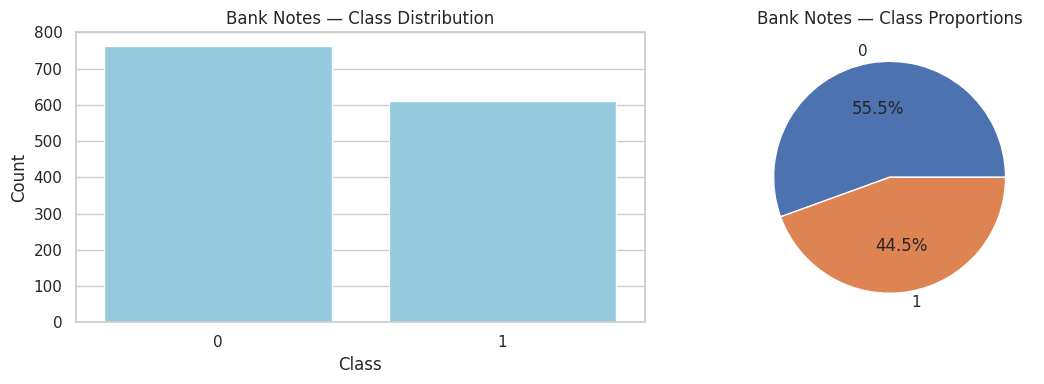

In [5]:
# Bar and pie charts for class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=target_col, ax=axes[0], color="skyblue")
axes[0].set_title("Bank Notes — Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

df[target_col].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[1])
axes[1].set_title("Bank Notes — Class Proportions")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Output description — Class distribution (4–6 lines):**  
The bar chart shows the number of bank note samples in each class.  
The pie chart displays the percentage proportion of each class.  
These plots help determine whether the target classes are balanced.  
Class balance should be considered when interpreting the model's evaluation metrics.

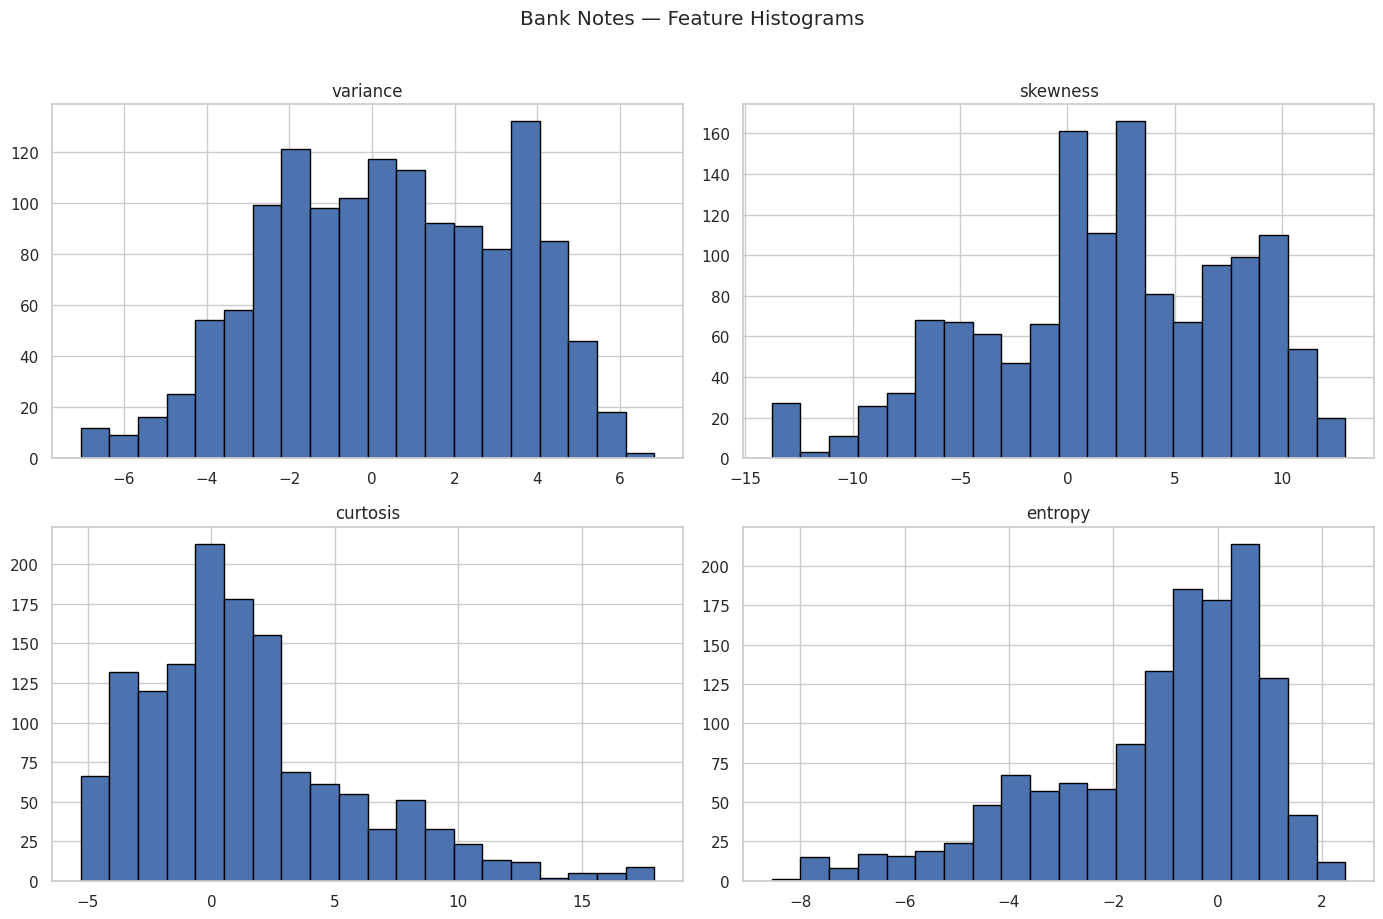

In [6]:
# Numeric feature histograms (excluding the target when it is numeric)
numeric_df = df.select_dtypes(include=np.number)
numeric_features = [c for c in numeric_df.columns if c != target_col]

if numeric_features:
    df[numeric_features].hist(figsize=(14, 9), bins=20, edgecolor="black")
    plt.suptitle("Bank Notes — Feature Histograms", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric feature columns available for histograms.")

**Output description — Histograms (4–6 lines):**  
The histograms show how the numerical features are distributed.  
They help reveal skewness, clusters, and differences in feature ranges.  
The plots provide a visual summary of the inputs used by the classifier.  
These patterns can help explain how the dataset may be separated into classes.

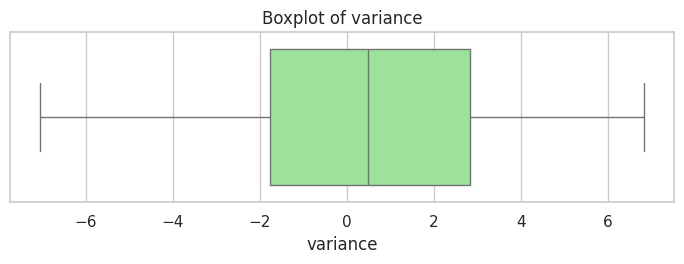

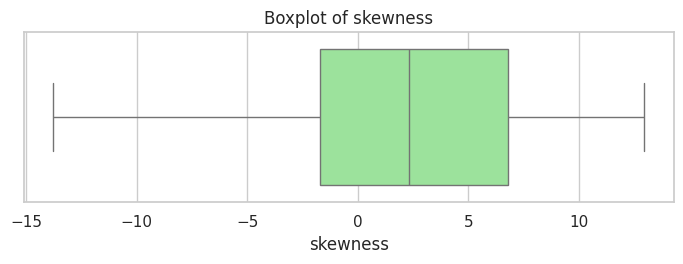

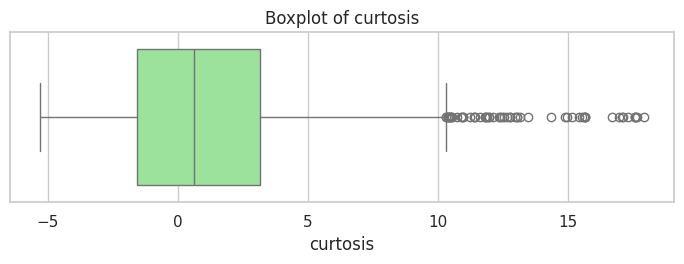

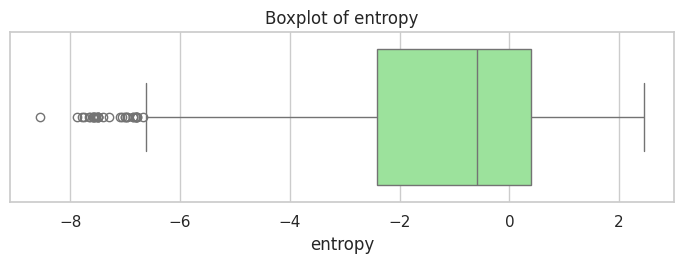

In [7]:
# Boxplots to inspect potential outliers
for col in numeric_features:
    plt.figure(figsize=(7, 2.8))
    sns.boxplot(x=df[col], color="lightgreen")
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

**Output description — Boxplots (4–6 lines):**  
Boxplots summarize the median, quartiles, and spread of each numeric feature.  
Points beyond the whiskers may indicate potential outliers.  
Outliers are inspected rather than automatically removed.  
This helps understand feature variation before fitting the model.

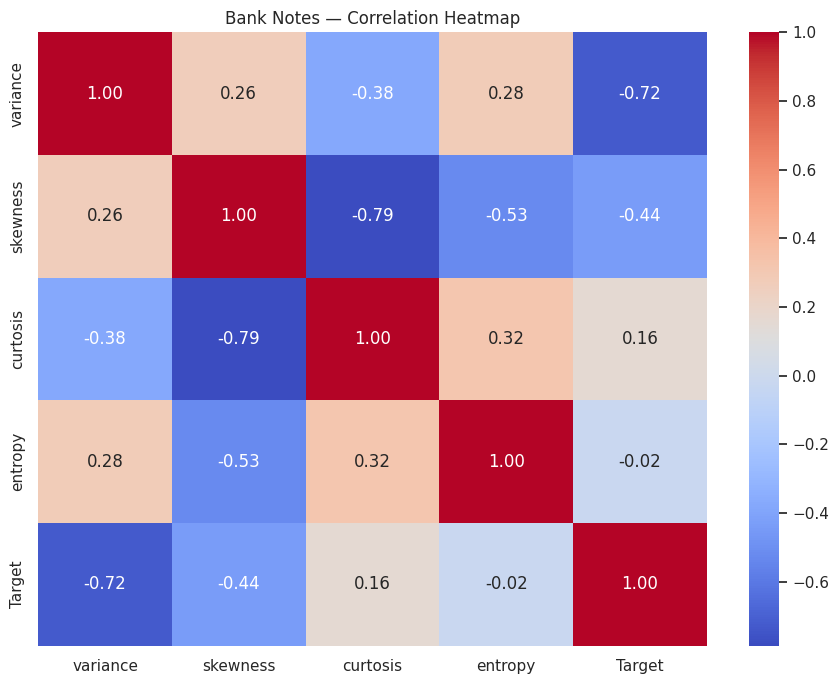

In [8]:
# Correlation heatmap
numeric_for_corr = df.select_dtypes(include=np.number)
if numeric_for_corr.shape[1] >= 2:
    plt.figure(figsize=(9, 7))
    sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Bank Notes — Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric columns are required for a correlation heatmap.")

**Output description — Correlation heatmap (4–6 lines):**  
The heatmap summarizes pairwise linear correlations among numerical columns.  
Positive values indicate features tend to increase together, while negative values indicate an inverse relationship.  
Values close to zero suggest weaker linear associations.  
The heatmap is descriptive and does not prove that one feature causes another to change.

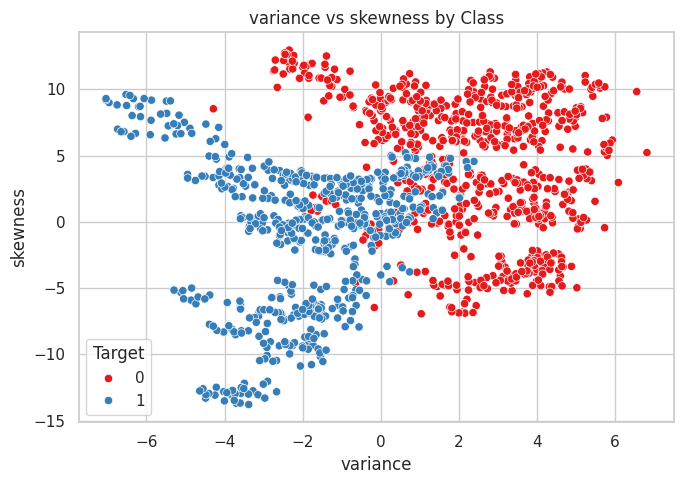

In [9]:
# Scatter plot of the first two numeric input features, colored by target
if len(numeric_features) >= 2:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=numeric_features[0], y=numeric_features[1],
                    hue=target_col, palette="Set1")
    plt.title(f"{numeric_features[0]} vs {numeric_features[1]} by Class")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numeric feature columns are needed for a scatter plot.")

**Output description — Scatter plot (4–6 lines):**  
Each point represents one bank note sample and is positioned by two numeric features.  
Colors indicate the class label.  
Visible clusters suggest the selected features may help distinguish classes.  
Overlap between colors indicates that these two features alone may not perfectly separate the classes.

## 4. Prepare the Data and Split the Dataset

In [10]:
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

# Remove records with missing target labels.
valid_target = y.notna()
X = X.loc[valid_target]
y = y.loc[valid_target].astype(str)

stratify_y = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=stratify_y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training feature shape: (1097, 4)
Testing feature shape: (275, 4)
Training labels: (1097,)
Testing labels: (275,)


**Output description — Train-test split (4–6 lines):**  
The data is split into training and testing subsets.  
The training subset is used to fit the classifier, while the test subset is reserved for evaluation.  
Stratification is applied when possible to preserve class proportions.  
This provides a more realistic estimate of performance on unseen samples.

## 5. Train the Gaussian Naïve Bayes Classifier

In [11]:
nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GaussianNB())
])

nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)

print("Gaussian Naïve Bayes training completed.")

Gaussian Naïve Bayes training completed.


**Output description — Model training (4–6 lines):**  
The pipeline fills missing input values using the median learned from training data.  
Gaussian Naïve Bayes estimates class probabilities from the training examples.  
The fitted classifier predicts the class labels of the held-out test records.  
These predictions are used in the following evaluation section.

## 6. Evaluate the Model

In [12]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Weighted Precision:", round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("Weighted Recall:", round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("Weighted F1-score:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8582
Weighted Precision: 0.858
Weighted Recall: 0.8582
Weighted F1-score: 0.858

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87       153
           1       0.85      0.83      0.84       122

    accuracy                           0.86       275
   macro avg       0.86      0.86      0.86       275
weighted avg       0.86      0.86      0.86       275



**Output description — Evaluation metrics (4–6 lines):**  
Accuracy reports the proportion of test records classified correctly.  
Weighted precision and recall summarize the results across classes, accounting for class support.  
The weighted F1-score combines precision and recall.  
The classification report provides additional class-wise results for a more detailed evaluation.

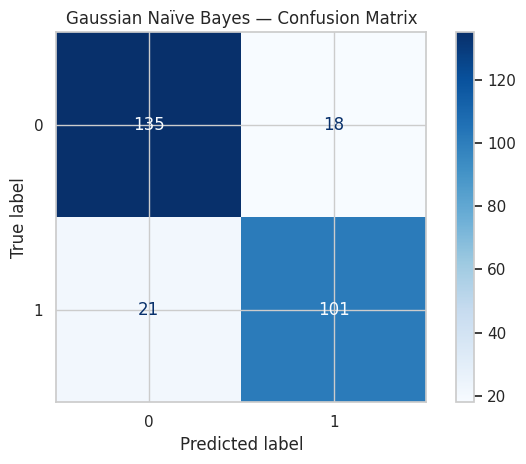

In [13]:
# Confusion matrix
labels = nb_model.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Gaussian Naïve Bayes — Confusion Matrix")
plt.tight_layout()
plt.show()

**Output description — Confusion matrix (4–6 lines):**  
The confusion matrix compares actual classes with the predicted classes.  
Diagonal entries represent correct predictions.  
Off-diagonal entries represent misclassified bank note samples.  
It helps identify which classes the model is most likely to confuse.

In [14]:
# Display a sample of actual and predicted labels
comparison = pd.DataFrame({
    "Actual Class": y_test.reset_index(drop=True),
    "Predicted Class": pd.Series(y_pred).reset_index(drop=True)
})
display(comparison.head(10))

,Actual Class,Predicted Class
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,0
6,0,0
7,0,0
8,0,1
9,1,1


**Output description — Actual vs predicted labels (4–6 lines):**  
This table compares actual labels with predictions for sample test records.  
Matching values indicate correct predictions, while different values indicate errors.  
It offers a record-level view of classifier behavior.  
Use this together with the confusion matrix and metrics for the final interpretation.

## 7. GitHub Repository

**GitHub Repository URL:** https://github.com/kulkarniaayush90-sys/Machine-Learning-Lab-7.git

**Notebook file:** `Lab_7(ML)_Complete.ipynb`

**Description:** This notebook implements Gaussian Naïve Bayes classification on `bank_notes.csv`, including EDA, preprocessing, training, evaluation, and visualizations.

After uploading the notebook to GitHub, replace the placeholder with your actual repository URL.

## 8. Viva Questions with Answers

**1. What is Bayes' theorem?**  
Bayes' theorem calculates the probability of a class given observed evidence using prior probability and likelihood.

**2. Why is Naïve Bayes called “naïve”?**  
It assumes that features are conditionally independent given the class, which is a simplifying assumption.

**3. What is Gaussian Naïve Bayes?**  
It is a Naïve Bayes variant that models each continuous feature with a Gaussian (normal) distribution within each class.

**4. What is a confusion matrix?**  
A confusion matrix compares actual and predicted classes, showing correct and incorrect predictions for each class.

**5. What is one advantage of Naïve Bayes?**  
It is computationally efficient, easy to train, and often performs well as a baseline classifier.

## 9. Conclusion
The Gaussian Naïve Bayes classifier was implemented using the bank notes dataset. EDA was performed before training to inspect data quality, class balance, feature distributions, potential outliers, and correlations. The model was evaluated using accuracy, weighted precision, weighted recall, weighted F1-score, a classification report, and a confusion matrix.

**Before submission:** Run all cells, check the generated metrics, capture output screenshots using a light theme, and upload the notebook to GitHub. Replace the GitHub URL placeholder with your actual repository URL.